# 03. Serving the fine-tuned model with Ray Serve

**AI Drug Discovery & Development Summit 2026 · Hands-on workshop · Part 3 of 3**

**Workshop series:** [01 Ray and offline inference](01_ray_and_offline_inference.ipynb) · [02 Train and tune](02_train_and_tune.ipynb) · [03 Serve](03_serve.ipynb)

Notebook 02 produced a fine-tuned checkpoint. This notebook puts it behind an endpoint a chemist can use:
the 3D results viewer, prediction from Python, and swapping checkpoints without breaking what is already
in use.

| § | Topic | Ray library | Min |
|---|---|---|---|
| 0 | Setup | | 2 |
| 6 | Serving the fine-tuned model | Ray Serve | 17 |
| 7 | Summary and next steps | | 5 |

Section numbers follow the workshop as a whole, so this notebook starts at Section 6.


## 0. Setup

- The Workspace runs the `aiddd-boltz2-of3` image: Ray, Boltz-2 and 2 OpenFold3 versions (0.5 and 0.4.3).
- This notebook runs on a CPU-only head node. L4 GPU nodes join when a cell requests a GPU and leave when idle.
- Data, model weights and all benchmark results live on shared storage.

In [12]:
import os, sys, json, time, warnings, subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import ray

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 60)

from aiddd_pipeline import (
    SHARED,
    TARGETS,
    BOLTZ_CACHE,
    OF3_OB_CKPT,
    OF3_P2_CKPT,
    OF3_FT_CKPT,
    OF3_OURS_CKPT,
    OF3_LEGACY,
    Boltz2Predictor,
    OF3Predictor,
    load_ligands,
    validate,
    make_scorer,
)
import workshop_helpers as wh

# Data and weights are downloaded once, ahead of the workshop (README step 2)
needed = [TARGETS[t].path("metadata") for t in wh.TARGET_KEYS] + [
    BOLTZ_CACHE,
    OF3_OB_CKPT,
    OF3_P2_CKPT,
    OF3_FT_CKPT,
    OF3_OURS_CKPT,
]
missing = [str(p) for p in needed if not p.exists()]
assert (
    not missing
), f"Missing {missing}. Run `python scripts/setup_data.py` and `python scripts/prepare_mpro.py` first."

# True: run every GPU step live (the presenter, or anyone with their own GPUs).
# False: GPU steps load stored results. Serving is notebook 03.
USE_GPUS = False
PRESENTER = True  # True: §6.6 runs the demo's in-place updates on the shared Service (the presenter only)
SERVICE_NAME = "aiddd-viewer"  # the shared Anyscale Service for §6: viewer page and prediction API at one URL
GPU = "L4"  # GPU type for every GPU step in this notebook

# The Service's URL: AIDDD_SERVICE_URL if set, otherwise looked up by name, as `anyscale service status` does
SERVICE_URL = os.environ.get("AIDDD_SERVICE_URL", "")
if not SERVICE_URL:
    try:
        import anyscale

        SERVICE_URL = anyscale.service.status(name=SERVICE_NAME).query_url or ""
    except Exception:  # no access to the Service from this workspace
        pass

wh.MINE.mkdir(parents=True, exist_ok=True)
print(f"shared data:  {SHARED}")
print(f"your outputs: {wh.MINE}")
print(
    f"viewer:       {SERVICE_URL or 'not found. Set AIDDD_SERVICE_URL to the URL the presenter shares, then re-run Setup.'}"
)

try:
    ray.init(
        runtime_env={"env_vars": {"AIDDD_SHARED": str(SHARED)}},
        ignore_reinit_error=True,
        logging_level="ERROR",
    )
except ValueError:  # inside an Anyscale Job, which already sets the environment
    ray.init(ignore_reinit_error=True, logging_level="ERROR")
dashboard = (
    os.environ.get("RAY_OVERRIDE_DASHBOARD_URL")
    or ray.get_runtime_context().dashboard_url
)
print(
    f"Ray Dashboard metrics: {dashboard.rstrip('/')}/#/metrics   (open in a new browser tab)"
)

(autoscaler +13m28s) [autoscaler] Cluster upscaled to {16 CPU, 2 GPU}.
shared data:  /mnt/shared_storage/aiddd
your outputs: /mnt/shared_storage/aiddd/workshop/geoff_counihan_a37252d
viewer:       https://aiddd-viewer-5ms2e.cld-g54aiirwj1s8t9kt.s.anyscaleuserdata.com
Ray Dashboard metrics: https://session-qh8knzhnqzglvz1agdye1hm7l3.i.anyscaleuserdata.com/#/metrics   (open in a new browser tab)


In [6]:
# Context from notebooks 01 and 02, loaded here so this notebook stands alone
results = {t: wh.load_results(t) for t in wh.TARGET_KEYS}
ev71 = results["ev71-2a"]
x7259a = ev71[ev71.complex_name == "A71EV2A-x7259a"].iloc[
    0
]  # the late follow-on used in 6.3 to 6.5
print("loaded benchmark results:", ", ".join(results))

loaded benchmark results: ev71-2a, sars2-mpro, mers-mpro


## 6. Serving with Ray Serve: one base model, many specialists

⏱ **Budget: 17 minutes.**

A chemist does not want a different endpoint per model. Ray Serve **model multiplexing** serves the general
**base model** and every program's **specialist** from one deployment, whose replicas share the GPUs: each
request names its model by **model ID**. Here that deployment runs in one shared Anyscale Service: everyone
sends requests to it, and only the presenter updates it.

| Step | Event | What happens |
|---|---|---|
| Start | Service created (the first time only) and set to step 1: base model only | `aiddd-viewer` on 2 L4 GPUs; this notebook and the viewer page share its URL (printed by Setup) |
| 6.1 | The multiplexed deployment's code | One deployment serves many models; each request names one by model ID |
| 6.2 | The compounds | 6 molecules with crystal structures: the answer key |
| 6.3 | Request sent: x7259a to the base model | Pose 5.2 Å from the crystal: wrong |
| 6.4 | Service updated in place: our fine-tune (`ev71-v1`) added. Request sent to it | Live 10 to 35 s later, no restart; 1.0 Å |
| 6.5 | Service updated in place: the public fine-tune (`ev71-v2`) added. Request sent to it | 0.4 Å |
| 6.6 | How the Service is built | One request composed from CPU prep, two GPU models and scoring; the viewer page shows the step |
| 6.7 | Requests sent by the whole room at once | Every answer from the cache, under a second |
| 6.8 | What comes next | Scaling each model to its speed, more models, always-loaded versions, GPUs across zones |

Answers come from a cache of poses computed before the session, so requests add no GPU work.


In [ ]:
# The presenter, before the first request: create the shared Service if it does not exist yet (5 to 10 min,
# once), then put it on step 1, the base model only (about 30 s, in place)
if PRESENTER:
    !anyscale service status -n aiddd-viewer > /dev/null 2>&1 || anyscale service deploy -f jobs/service.yaml
    !anyscale service wait -n aiddd-viewer --state RUNNING
    !anyscale service deploy -f jobs/demo_1_base.yaml --in-place

### 6.1 A multiplexed deployment

**Ray Serve in brief.** A Serve **application** is one or more **deployments**. A deployment is a Python class;
Serve runs it as **replicas** (Ray actors, each with the CPUs and GPUs it asks for) and spreads requests across
them, scaling the number of replicas with traffic. Requests arrive over HTTP or through a **deployment
handle** from Python. On Anyscale, a **Service** runs one or more applications behind a stable URL and updates
them without downtime.

**A standard deployment versus a multiplexed one.** A standard deployment serves one model: each replica loads
it once, in `__init__`, and every replica is the same. Ten models means ten deployments, each with its own
replicas and GPUs, mostly idle. A **multiplexed** deployment serves many models from the same replicas: each
request carries a **model ID**, a replica loads that model on its first request and keeps it, and Serve
routes later requests for that ID to a replica that already has it loaded. The number of models is no longer
tied to the number of deployments or GPUs, and a new model is a new ID, not a new deployment.

**The code.** `@serve.multiplexed` is the whole mechanism. `__call__` reads the model ID a request asked for with
`serve.get_multiplexed_model_id()`, and `load` turns that ID into a model: here it builds OpenFold3 and reads
the checkpoint once (10 to 70 s, most of it reading the file). Serve caches what `load` returns per model ID
on each replica. Past `max_num_models_per_replica` (2 here), a new model ID evicts the least recently used one,
and Serve calls its `__del__`, which frees it.

The registry (`user_config`) lists the base model and both specialists. Nothing loads until a request
asks for a model ID. In production, adding a model ID to a running deployment is a config change; the Service at the end
of this section does it in place, with no restart.

The replica runs in a different Python from this notebook: OF3-p2 checkpoints only load in OpenFold3
0.4.x, installed separately in the image. `runtime_env={"py_executable": ...}` gives this one deployment
that interpreter; nothing else changes. The slow work runs in a thread (`asyncio.to_thread`), so the
replica keeps answering Ray Serve's health and queue checks while a model loads.

In [13]:
import asyncio
from ray import serve
from aiddd_pipeline import (
    LIVE_MODELS,
    OF3_LEGACY_PY,
)  # model id -> {version, name, checkpoint}
from of3_live import LiveModel  # OpenFold3 with its weights loaded, and a pose cache


@serve.deployment(
    ray_actor_options={
        "num_gpus": 0.5,
        "accelerator_type": "L4",
        "runtime_env": {"py_executable": OF3_LEGACY_PY},
    }
)  # OpenFold3 0.4.x
class PoseModel:
    def reconfigure(self, models):  # {model_id: {version, name, checkpoint}}
        self.models = models

    @serve.multiplexed(
        max_num_models_per_replica=2
    )  # 2 models in memory; a third evicts the least used
    async def load(self, model_id):  # builds OpenFold3 and reads the checkpoint, once
        return await asyncio.to_thread(LiveModel, self.models[model_id])

    async def __call__(self, smiles, fresh=False):
        model = await self.load(serve.get_multiplexed_model_id())
        return await asyncio.to_thread(
            model, smiles, fresh
        )  # pose, plus where it came from


models = dict(
    LIVE_MODELS
)  # base, ev71-v1, ev71-v2: registered now, each loaded on its first request
if USE_GPUS:  # the presenter: this application, on the workshop's GPUs
    handle = serve.run(
        PoseModel.options(user_config=models).bind(),
        name="aiddd-pose",
        route_prefix=None,
    )  # called by handle from this notebook only, no HTTP route
else:  # everyone else: the shared Service runs the same kind of deployment, for the whole room
    handle = None
    print(
        "The presenter runs this deployment on GPUs. Your requests in this section go to the shared Service:",
        SERVICE_URL
        or "not set yet. Set AIDDD_SERVICE_URL (README, Workshop format) and re-run Setup.",
    )

The presenter runs this deployment on GPUs. Your requests in this section go to the shared Service: https://aiddd-viewer-5ms2e.cld-g54aiirwj1s8t9kt.s.anyscaleuserdata.com


### 6.2 Compounds for the demo

All are EV-A71 2A late follow-ons with a crystal structure, so you can compare the prediction with the
experiment. None was in either fine-tune's training set (the fragment screen).

| Compound | Base model | Our fine-tune (v1) | Public fine-tune (v2) | SMILES |
|---|---|---|---|---|
| **x7259a**, the demo: most potent here (pKD 7.9) | 5.2 Å | 1.0 Å | 0.4 Å | `CSc1ncnc(N2CCC[C@@H]2C2CC2)c1CC(=O)N1CCC[C@H](C(N)=O)C1` |
| **x7608a** | 4.8 Å | 0.3 Å | 0.5 Å | `CSc1ncnc(N(C)CC(F)(F)F)c1CC(=O)N1C[C@@H](C(N)=O)C[C@@H]2C[C@@H]21` |
| **x7024a** | 6.1 Å | 1.1 Å | 0.8 Å | `CSc1ncnc(N2CCC3(CCCC3)C2)c1CC(=O)N1CCC[C@H](C(N)=O)C1` |
| **x6714a** | 4.7 Å | 0.9 Å | 0.4 Å | `NC(=O)[C@H]1CCC(=O)N(c2cc3cnccc3c(F)c2F)C1` |
| **x7011a** | 4.8 Å | 1.4 Å | 0.5 Å | `CC[C@H]1CCCN1c1ncnc(SC)c1CC(=O)N1CCC[C@H](C(N)=O)C1` |
| **x7101a**, harder: only v2 gets it | 6.2 Å | 4.3 Å | 0.8 Å | `CSc1ncnc(N2CCC3(CCCCC3)C2)c1CC(=O)N1CCC[C@H](C(N)=O)C1` |

Ligand RMSD to the crystal, through the shared Service; under 2 Å is a correct pose. One diffusion sample,
seed 42, as this notebook runs them; a new live run of the same molecule differs by about 0.2 Å.

### 6.3 Predict with the base model, live

Each request names its model: `"model": "base"` in the HTTP request to the Service, or
`handle.options(multiplexed_model_id="base")` through a Ray Serve handle. The base model has never seen this
pocket with a ligand in it, so on an EV-A71 2A follow-on it is usually wrong.

Poses are cached per model version, and every step was run once before the session, so most answers come
back at once. On the presenter's screen this step runs live on purpose: with `PRESENTER = True` the cell
first removes this pose from the Service's cache, so the Service computes it and you see the real cost.
Your copy is answered from the cache. Each answer says who answered and how.

**To show it live again** (the presenter): remove this pose from the Service's cache, then re-run the next cell.
With `PRESENTER = True` the next cell does it for you. From a terminal:

```bash
curl -X POST https://aiddd-viewer-5ms2e.cld-g54aiirwj1s8t9kt.s.anyscaleuserdata.com/cache/clear \
     -H 'Content-Type: application/json' -d '{"compound": "x7259a", "model": "base"}'
```

It removes only that molecule's pose for that model; everything else stays cached.


x7011a, base model: the Service aiddd-viewer answered with Base model: OF3-p2 145k, from its pose cache, no GPU work; 4.8 Å from the crystal; GPU in us-west-2d



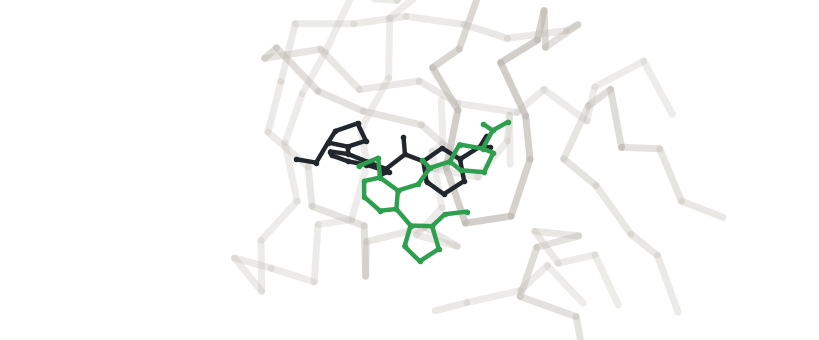

In [24]:
import requests

DEMO_COMPOUNDS = {
    "x7259a": "CSc1ncnc(N2CCC[C@@H]2C2CC2)c1CC(=O)N1CCC[C@H](C(N)=O)C1",
    "x7608a": "CSc1ncnc(N(C)CC(F)(F)F)c1CC(=O)N1C[C@@H](C(N)=O)C[C@@H]2C[C@@H]21",
    "x7024a": "CSc1ncnc(N2CCC3(CCCC3)C2)c1CC(=O)N1CCC[C@H](C(N)=O)C1",
    "x6714a": "NC(=O)[C@H]1CCC(=O)N(c2cc3cnccc3c(F)c2F)C1",
    "x7011a": "CC[C@H]1CCCN1c1ncnc(SC)c1CC(=O)N1CCC[C@H](C(N)=O)C1",
    "x7101a": "CSc1ncnc(N2CCC3(CCCCC3)C2)c1CC(=O)N1CCC[C@H](C(N)=O)C1",
}
# choose compound to predict
compound = "x7011a"  # "x7259a"
smiles = DEMO_COMPOUNDS[compound]
ev71 = results["ev71-2a"]
compound_data = ev71[ev71.complex_name == f"A71EV2A-{compound}"].iloc[0]


def show(out, label):
    """Who answered and how, in one line, then the predicted pose (green) over the crystal (orange)."""
    if out.get("status") == "failed":
        if "unknown model id" in out["error"]:
            print(
                f"{label}: not on the Service yet. The presenter adds it in this step; run the cell again after."
            )
        else:
            print(f"{label}: {out['error']}")
        return
    who = f"the Service {SERVICE_NAME}" if "pose_model" in out else "your deployment"
    how = (
        "from its pose cache, no GPU work"
        if out["source"] == "cache"
        else f"live in {out['seconds']:.0f} s"
        + (
            f", {out['load_seconds']:.0f} s of it loading the model"
            if out["load_seconds"]
            else ""
        )
    )
    rmsd = (out.get("answer_key") or {}).get("lig_rmsd")
    print(
        f"{label}: {who} answered with {out['model']['name']}, {how}"
        + (f"; {rmsd:.1f} Å from the crystal" if rmsd is not None else "")
        + (f"; GPU in {out['zone']}" if out.get("zone") else "")
    )
    if (
        out.get("format") == "pdb"
    ):  # the Service sends the pose already moved onto the crystal
        wh.show_aligned(out["cif"], compound_data, label=label, height=340)
    else:  # your deployment sends the raw prediction
        wh.show_analog(out["cif_path"], compound_data, label=label, height=340)


if (
    PRESENTER
):  # remove this pose from the Service's cache, so the Service computes it live
    requests.post(
        f"{SERVICE_URL}/cache/clear",
        json={"compound": compound, "model": "base"},
        timeout=60,
    )

if (
    USE_GPUS
):  # your own deployment, through its Ray Serve handle (fresh: run the model even if cached)
    out = await handle.options(multiplexed_model_id="base").remote(smiles, fresh=True)
else:  # the shared Anyscale Service, over HTTP, as the viewer page calls it
    out = requests.post(
        f"{SERVICE_URL}/predict",
        json={"smiles": smiles, "model": "base"},
        timeout=900,
    ).json()
show(out, f"{compound}, base model")

### 6.4 The program's specialist

Notebook 02 fine-tuned the base model on this program's fragment screen: model id `ev71-v1`. It loads on
the first request for its id, next to the base model, which stays loaded and keeps serving everyone else.

The presenter adds it to the shared Service in this cell: `demo_2_ft.yaml` registers `ev71-v1` and routes EV-A71 2A
requests to it, in place, with no restart. It answers 10 to 35 s later. Run the cell again once it has.


In [ ]:
if PRESENTER:  # add our fine-tune to the shared Service, in place: no restart
    !anyscale service wait -n aiddd-viewer --state RUNNING    # the previous update has finished
    !anyscale service deploy -f jobs/demo_2_ft.yaml --in-place
    while (
        requests.get(f"{SERVICE_URL}/models", timeout=10).json()["route"] != "ev71-v1"
    ):
        time.sleep(2)  # the new model answers in 10 to 35 s


In [25]:

if USE_GPUS:
    out = await handle.options(multiplexed_model_id="ev71-v1").remote(smiles)
else:
    out = requests.post(
        f"{SERVICE_URL}/predict",
        json={"smiles": smiles, "model": "ev71-v1"},
        timeout=900,
    ).json()
show(out, f"{compound}, our fine-tune")

x7011a, our fine-tune: not on the Service yet. The presenter adds it in this step; run the cell again after.


Same molecule, same endpoint, a different `multiplexed_model_id`: the pose moves from 5.2 Å off the
crystal to 1.0 Å. One replica now holds both models.

### 6.5 A newer version

A stronger fine-tune arrives (here, the OpenBind release: 0.4 Å on x7259a, and it also gets x7101a), under
its own id, `ev71-v2`. v1 stays reachable by id, for a rollback or a canary. The replica keeps 2 models in
memory, so loading v2 evicts the least recently used one: the base model. Its checkpoint is a 6.7 GB
file that also carries training state, so it takes 20 to 70 s to load; the next request is a normal 25 s prediction.

The presenter adds it in this cell with `demo_3_next_ft.yaml`, again in place.


In [ ]:
if PRESENTER:  # add the public fine-tune to the shared Service, in place: no restart
    !anyscale service wait -n aiddd-viewer --state RUNNING    # the previous update has finished
    !anyscale service deploy -f jobs/demo_3_next_ft.yaml --in-place
    while (
        requests.get(f"{SERVICE_URL}/models", timeout=10).json()["route"] != "ev71-v2"
    ):
        time.sleep(2)  # the new model answers in 10 to 35 s

if USE_GPUS:
    out = await handle.options(multiplexed_model_id="ev71-v2").remote(smiles)
else:
    out = requests.post(
        f"{SERVICE_URL}/predict",
        json={"smiles": smiles, "model": "ev71-v2"},
        timeout=900,
    ).json()
show(out, f"{compound}, the public fine-tune")

On the presenter's deployment the eviction is visible: the base model was evicted to make room for v2, so the next base request loads
it again (and evicts v1, now the least recently used). Raise `max_num_models_per_replica`, or add
replicas, when more models are in steady use. The shared Service keeps all three loaded
(`MAX_RESIDENT = 3` in `serve_viewer.py`), so your copy of this cell answers from the cache.

x7011a, base model again: the Service aiddd-viewer answered with Base model: OF3-p2 145k, from its pose cache, no GPU work; 4.8 Å from the crystal; GPU in us-west-2d



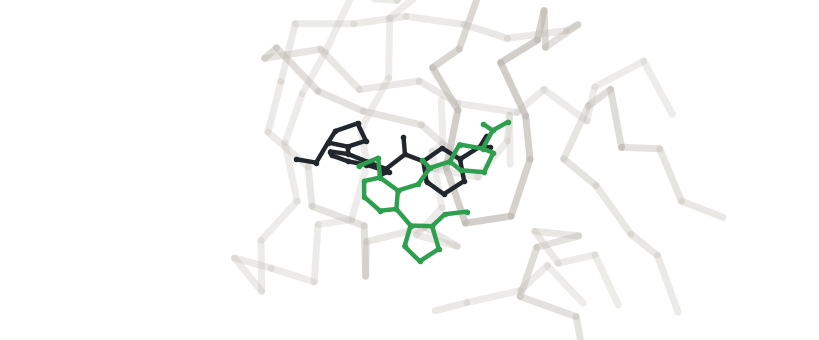

In [26]:
if USE_GPUS:
    out = await handle.options(multiplexed_model_id="base").remote(smiles)
else:
    out = requests.post(
        f"{SERVICE_URL}/predict",
        json={"smiles": smiles, "model": "base"},
        timeout=900,
    ).json()
show(out, f"{compound}, base model again")

### 6.6 How the Service is built

![The Service app: one request, composed across CPU and GPU deployments](docs/images/serve_composition.svg)

One request to the Service is composed from 3 deployments in one Python app (`Viewer.predict` in
`serve_viewer.py`). The Viewer prepares the molecule with RDKit on CPU, calls OpenFold3 and Boltz-2 at the
same time on GPUs, then scores the pose against the crystal.

- **`OF3Pool`** is the deployment from 6.1 plus what a shared service needs: a cached pose is answered
  without loading a model, live predictions take turns on the GPU, and 3 models stay in memory.
- **Each deployment declares its own resources and scales on its own.** `OF3Pool` asks for a whole L4, so its
  loaded models have that node's memory to themselves; Boltz-2 takes half an L4 on the other node.
- **Each deployment can have its own Python** (`runtime_env`): OpenFold3 0.4.x next to Boltz-2 in the
  image's Python. An existing model joins the app as it is.
- **Only `user_config` changed in 6.4 and 6.5**, so `--in-place` reached the running replicas through
  `reconfigure()`. A change to code or the image is a full `anyscale service deploy`, which can shift traffic
  gradually (`--canary-percent`) or roll back (`anyscale service rollback`). Between in-place steps, edit no
  Python file: the upload would carry a code change and restart every replica.

| What Ray Serve and Anyscale add | Why it matters |
|---|---|
| **Model multiplexing** | The base model and every specialist on the same GPUs, chosen per request |
| **In-place updates** | A new model through `user_config` and `reconfigure()`: no restart, no new nodes |
| **Composition** | CPU prep and scoring around 2 GPU models, in one Python app |
| **A Python environment per deployment** | OpenFold3 0.4.x and Boltz-2 side by side, no new image |
| **GPUs from every zone** | When one zone runs out of L4s, nodes start in another |
| **Canary rollouts and rollback** | A new version reaches a share of users first |


In [27]:
# Where the shared Service is now: its demo step, the model id EV-A71 2A requests go to, and the models in memory
if SERVICE_URL:
    m = requests.get(f"{SERVICE_URL}/models", timeout=60).json()
    print(
        f"{m.get('step') or 'not on a demo step'} | route: {m['route']} | in memory: {m['resident']} | "
        f"OpenFold3 GPU in {m['zone']} | viewer: {SERVICE_URL}"
    )

demo_1: base model only | route: base | in memory: [] | OpenFold3 GPU in us-west-2d | viewer: https://aiddd-viewer-5ms2e.cld-g54aiirwj1s8t9kt.s.anyscaleuserdata.com


### 6.7 Your turn: the shared Service

The same Service the viewer page uses also answers Python. This cell sends the 6.2 compounds for 2 model
ids, the base model and the id EV-A71 2A requests go to now, 8 at a time, as the whole room does at
once. Every answer comes from the pose cache, so it adds no GPU work.

In [28]:
import concurrent.futures as cf

if not SERVICE_URL:
    print("Skipped. Set AIDDD_SERVICE_URL (README, Workshop format) and re-run Setup.")
else:
    url = SERVICE_URL.rstrip("/")
    route = requests.get(f"{url}/models", timeout=60).json()["route"]
    ids = ["base"] + ([route] if route != "base" else [])

    def ask(job):
        compound, model_id = job
        t0 = time.time()
        r = requests.post(
            f"{url}/predict",
            json={"smiles": DEMO_COMPOUNDS[compound], "model": model_id},
            timeout=900,
        )
        j = r.json() if r.ok else {}
        return {
            "compound": compound,
            "model id": model_id,
            "RMSD (Å)": (j.get("answer_key") or {}).get("lig_rmsd"),
            "source": j.get("source", f"HTTP {r.status_code}"),
            "seconds": round(time.time() - t0, 2),
            "zone": j.get("zone"),
        }

    with cf.ThreadPoolExecutor(8) as ex:
        room = pd.DataFrame(ex.map(ask, [(c, m) for c in DEMO_COMPOUNDS for m in ids]))
    display(
        room.pivot(index="compound", columns="model id", values="RMSD (Å)").round(2)
    )
    display(room)

model id,base
compound,
x6714a,4.73
x7011a,4.78
x7024a,6.07
x7101a,6.17
x7259a,5.20
x7608a,4.77


,compound,model id,RMSD (Å),source,seconds,zone
0,x7259a,base,5.195467,cache,0.31,us-west-2d
1,x7608a,base,4.768109,cache,1.09,us-west-2d
2,x7024a,base,6.068148,cache,1.11,us-west-2d
3,x6714a,base,4.733443,cache,1.09,us-west-2d
4,x7011a,base,4.781443,cache,0.05,us-west-2d
5,x7101a,base,6.174623,cache,1.07,us-west-2d


**What to watch while the room runs requests.** On the Service's page in the Anyscale console, open the
metrics dashboards (Grafana). The *Serve* dashboard:

| Panel | What it shows during the exercise |
|---|---|
| QPS per deployment | Each Viewer request becomes one OF3Pool call and one Boltz2Live call |
| P50 / P90 / P99 latency per deployment | Cached answers stay low; a live prediction shows as a long tail |
| Queue size per deployment | Requests waiting for a replica |
| Replicas per deployment | The Viewer scales from 2 to 4 replicas on CPU as the room arrives; the GPU replicas stay fixed |

The *Serve Deployment* dashboard shows multiplexing itself: *Multiplexed models per replica*, *Multiplexed
model loads per replica* and *Multiplexed model cache hit rate* for OF3Pool.

### 6.8 What comes next

The room's requests came from the cache. Real use means new molecules, more programs and more versions.

- **Scale each model to its own speed.** A new molecule needs both GPU models. OpenFold3 computes a pose in
  about 25 s with its model loaded; Boltz-2 takes 1 to 2 minutes for the same molecule. So Boltz-2 is the
  bottleneck: in *Queue size per deployment* its queue grows first, and it needs several replicas for each
  OpenFold3 replica. No coordination is needed: each deployment autoscales on its own queue
  (`autoscaling_config`), so the slower one grows first. Raise each `max_replicas` and the node group's
  `max_nodes`. Host memory sets the packing: a live Boltz-2 prediction takes a 32 GB L4 node to about 18 GB,
  so one Boltz-2 replica per node, or larger nodes.
- **More models.** Multiplexing keeps the number of models independent of the number of deployments. Each
  loaded OpenFold3 model adds about 3 GB of host memory. With more replicas, Serve sends each model ID to a
  replica that already holds it, so the models spread across replicas. *Multiplexed model cache hit rate* and
  *Multiplexed model loads per replica* show when there are more models in use than replicas hold: raise
  `max_num_models_per_replica` or add replicas.
- **Keep each program's current version always loaded.** Multiplexing evicts the least recently used model; it
  has no pinning. The standard pattern: each program's current version in its own deployment
  (`min_replicas: 1`), and the multiplexed deployment for older versions and experiments. Or a short change to
  `OF3Pool`: a pinned list in `user_config`, loaded at startup and never evicted.
- **Release idle GPUs.** `min_replicas: 0` frees a deployment's GPU when no requests come; the next request
  waits for a GPU node to start and the model to load.
- **GPUs from several availability zones.** A zone is a separate data center in the region (us-west-2a, 2b, ...).
  `enable_cross_zone_scaling: true` lets Anyscale start the Service's nodes in any zone, so a shortage of L4s
  in one zone does not block it; L4 launches failed repeatedly in this workspace on Oct 26. The cost: traffic
  between zones adds latency and AWS bills it per GB. That matters for GPUs that talk to each other, such as
  multi-node training, which belongs in one zone. It does not matter here: each request is handled by one
  replica, so only requests and answers cross zones. Spread across zones also keeps the Service up if one zone
  fails, but only if the nodes land in different zones: Anyscale places them where capacity is.


## 7. Summary and next steps

**Findings**

- **Generalization.** On late follow-ons, Boltz-2 places 92% of SARS-CoV-2 Mpro poses within 2 Å of the
  crystal and 1% of EV-A71 2A poses (`wh.by_stage` on the stored benchmark). OpenBind-0 keeps 91% on EV-A71
  2A, most likely because related data was in its training set (notebook 01).
- **Fine-tuning.** 66 fragment-screen structures measurably improve OpenFold3 on held-out follow-on
  compounds (notebook 02), and the result is a specialist for that target.

**Delivered on a single Ray cluster**

- **Ray Data.** The full benchmark across 3 campaigns, and 402 new OpenFold3 predictions in 19 minutes on
  12 L4 GPUs.
- **Ray Train.** OpenFold3's own training code on 8 GPUs, with checkpoints and automatic recovery.
- **Ray Serve.** The base model and program specialists in one multiplexed deployment: chosen per
  request, the most recently used kept in memory. On an Anyscale Service, new versions are added in
  place with no restart, and canary rollouts are one flag.

The [README](README.md) has the scientific background and the full runbook. Run the next cell to stop the
presenter's Serve application and release the GPU nodes.

In [ ]:
if USE_GPUS:  # only the presenter started a Serve application
    serve.shutdown()
    print("Serve stopped. Idle GPU nodes will be released within a few minutes.")

# Presenter, before the next session: put the shared Service back on step 1
# !anyscale service deploy -f jobs/demo_1_base.yaml --in-place